# The BBP transition

Consider a signal $\beta v v^T$ in a noise matrix $W$. When can we see it in the eigenvalues?

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000                                   # size of the matrix
u = np.repeat([1.0, -1.0], n // 2)         # hidden groups: +1 / -1
np.random.shuffle(u)
v = u / np.sqrt(n)                         # normalised hidden direction

def noise(n):
    A = np.random.randn(n, n)
    return (A + A.T) / np.sqrt(2 * n)      # symmetric noise, eigenvalues in [-2, 2]

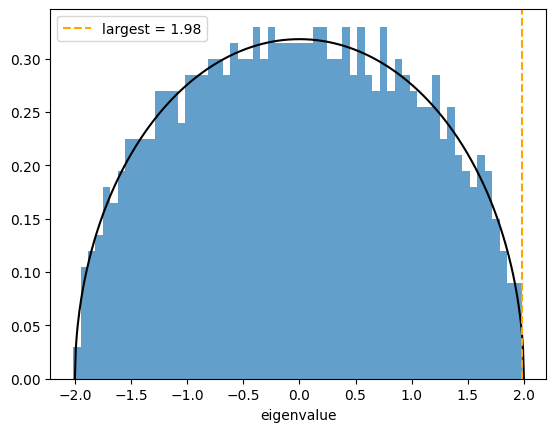

theory for the largest eigenvalue: 2.0
overlap with hidden groups: 0.005   theory: 0


In [6]:
beta = 0.5                     # examples: 0.5, 1.0, 1.5, 3.0
Y = beta * np.outer(v, v) + noise(n)
eigvals, eigvecs = np.linalg.eigh(Y)

x = np.linspace(-2, 2, 500)
plt.hist(eigvals, bins=60, density=True, alpha=0.7)
plt.plot(x, np.sqrt(4 - x**2) / (2 * np.pi), 'k')
plt.axvline(eigvals[-1], color='orange', ls='--', label=f'largest = {eigvals[-1]:.2f}')
plt.legend(); plt.xlabel('eigenvalue')
plt.show()

print('theory for the largest eigenvalue:', beta + 1/beta if beta > 1 else 2.0)
overlap = (eigvecs[:, -1] @ v) ** 2
print('overlap with hidden groups:', round(overlap, 3), '  theory:', max(0, 1 - 1 / beta**2))

**Questions:** (1) At which $\beta$ does the outlier appear?
(2) Use the sign of the top eigenvector to guess the groups: what fraction do you get right?
(3) Repeat with $n=200$ and $n=4000$: what changes near $\beta=1$?

In [7]:
guess = np.sign(eigvecs[:, -1])
accuracy = max(np.mean(guess == u), np.mean(guess == -u))   # the sign of an eigenvector is arbitrary
print('fraction of words in the right group:', accuracy)

fraction of words in the right group: 0.531
